# Class-wise Gaussianity with LeJEPA SIGReg

Companion to `Synthetic.ipynb`: use the same three synthetic Gaussian input
classes and nonlinear encoder, with a fixed spherical simplex LDA head
using the head default $\Sigma=I/D$ ($D=2$, so $\sigma^2=1/2$), Adam
optimizer, and snapshots at epochs 1, 5, 10, and 100. Compare **NLLLoss**,
**CovNLLLoss**, and **SIGRegNLLLoss** under matched initialization and batch order.

The new loss adapts **Sketched Isotropic Gaussian Regularization (SIGReg)** from
Balestriero and LeCun, *LeJEPA: Provable and Scalable Self-Supervised Learning
Without the Heuristics*, [local paper](LeJEPA.pdf), Section 4.2.3 and Algorithm 1
(PDF page 10; arXiv:2511.08544v3). We use its Gaussianity regularizer in this
supervised LDA experiment; no JEPA views or predictive loss are needed.

Run from `simplex-lda/` with PyTorch, NumPy, and Matplotlib installed.


## Setup and experiment settings


In [1]:
import json
import math
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, Subset

from lda import SimplexLDAHead, CovNLLLoss, class_covariance_penalty
from sigreg import ClasswiseSIGReg

TRAIN_SIZE, TEST_SIZE = 20_000, 4_000
BATCH_SIZE, EVAL_BATCH_SIZE = 256, 1024
PLOT_SIZE = 1000
checkpoint_epochs = (1, 5, 10, 100)
comparison_seed = 7
covariance_weight = 1.0
gaussianity_weight = 1.0
num_slices = 256
num_integration_points = 65
diagnostic_integration_points = 129
sigreg_warmup_epochs = 5
sigreg_ramp_epochs = 5
loss_names = ('NLLLoss', 'CovNLLLoss', 'SIGRegNLLLoss')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device =', device)


device = cuda


## Generate the same synthetic dataset


In [2]:
# Three Gaussian clusters in 2D with shared covariance.
C, separation = 3, 1.7
NUM_CLASSES = C
LABEL_OFFSET = 1
pi = torch.full((C,), 1.0 / C)
base_mus = torch.tensor([[-2.0, -0.5],
                         [ 2.2,  0.2],
                         [-0.5,  2.3]], dtype=torch.float32)
mus = base_mus * separation
Sigma = torch.tensor([[1.0, 0.35],
                      [0.35, 1.1]], dtype=torch.float32)
chol = torch.linalg.cholesky(Sigma)

def sample_dataset(n_total, seed):
    gen = torch.Generator().manual_seed(seed)
    ys = torch.multinomial(pi, n_total, replacement=True, generator=gen)
    noise = torch.randn((n_total, 2), generator=gen)
    x = noise @ chol.T + mus[ys]
    y = ys + LABEL_OFFSET
    perm = torch.randperm(n_total, generator=gen)
    return x[perm], y[perm]

train_X, train_y = sample_dataset(TRAIN_SIZE, seed=7)
test_X, test_y = sample_dataset(TEST_SIZE, seed=137)

train_ds = TensorDataset(train_X, train_y)
test_ds = TensorDataset(test_X, test_y)

train_ld = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_ld = DataLoader(test_ds, batch_size=EVAL_BATCH_SIZE, shuffle=False)

train_X[:5], train_y[:5]


(tensor([[-0.4112,  3.5449],
         [ 3.9778, -0.9086],
         [ 2.5725, -0.2544],
         [ 4.3941,  2.2189],
         [ 3.0573,  0.6371]]),
 tensor([3, 2, 2, 2, 2]))

## Same nonlinear encoder and fixed spherical-covariance LDA head


In [3]:
class Encoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32), nn.ReLU(inplace=True),
            nn.Linear(32, dim)
        )

    def forward(self, x):
        return self.net(x)

class DeepLDA(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = Encoder(D)
        self.head = SimplexLDAHead(C, D)  # Default fixed covariance I / D.

    def forward(self, x):
        z = self.encoder(x)
        return self.head(z)


## From global SIGReg to class-conditional Gaussianity

For each class $c$, form standardized residuals $r_i=(z_i-\mu_c)/\sigma$
using the **fixed simplex center** and **fixed model standard deviation**
$\sigma=1/\sqrt{D}$. Test each residual distribution separately against
$N(0,I)$, targeting $N(\mu_c,I/D)$ in embedding space.
Do not pool classes: a Gaussian residual mixture can conceal non-Gaussian
individual classes. We do not estimate class means or scales from the batch, so the
penalty also detects wrong means and variances.

Following Algorithm 1, sample $M=256$ unit directions $a_m$ afresh at every
minibatch. With $t_j$ the 65 evenly spaced points on $[-5,5]$, compute

\[
\widehat\phi_{c,m}(t)=\frac{1}{n_c}\sum_{i:y_i=c}
\exp\{it a_m^\top(z_i-\mu_c)/\sigma\},\qquad \phi_0(t)=e^{-t^2/2},
\]
\[
\mathrm{EP}_c=\frac{n_c}{M}\sum_{m=1}^M
\operatorname{trapz}_{t_j}\left[
\left|\widehat\phi_{c,m}(t)-\phi_0(t)\right|^2\phi_0(t)\right],
\qquad
\mathcal L=\mathcal L_{\rm NLL}+\lambda_G
\sum_c\frac{n_c}{N}\mathrm{EP}_c.
\]

`sigreg.py` implements this calculation using real and imaginary CF components
(`cos` and `sin`) and retains the paper's $n_c$ multiplier and Gaussian window.
Class-frequency weighting is our supervised adaptation. Absent classes and
singletons contribute zero; remaining weights are not renormalized.
All classes share the sampled directions but have separate empirical CFs.
A private seeded generator makes the regularizer reproducible without changing
model initialization or data shuffling. The final short batch is retained.

The baseline's `nn.NLLLoss` takes **unnormalized generative log scores** from the
head: $-\mathrm{mean}\,s_y(z)$. We keep that behavior, with no `log_softmax`.
CovNLLLoss applies the covariance penalty to $z/\sigma$, matching
standardized empirical covariance to identity (embedding covariance to
$I/D$); SIGReg also matches
distribution shape and the fixed class mean. Finite projections and a finite
regularization weight encourage Gaussianity rather than guarantee it exactly.
The $n_c$ scaling makes the strength batch-size dependent, so retune
`gaussianity_weight` if you change `BATCH_SIZE`. Set it to zero to recover NLL.

All three runs use `SimplexLDAHead(C, D)` without a covariance override.
The default is $\Sigma=I/D$, giving $\Sigma=0.5I_2$ in this 2D experiment.
There are no covariance parameters; encoder weights and class priors are
optimized. Penalties and diagnostics read the variance from `head.cov_diag`.


### Numerical integration and optimization

The original 17-point grid has frequency spacing $\Delta t=0.625$. In one
projection, its sampled characteristic function cannot distinguish translations
by $2\pi/\Delta t\approx10.05$ standardized units. Large standardized
residuals can therefore hide errors on a coarse grid.
This notebook uses **65 training points** (translation period about 40.2)
and **129 diagnostic points**, preserving the paper's integration range and
Gaussian window. These finer grids reduce the aliasing problem; any finite
uniform frequency grid still has a translation period.

For SIGRegNLLLoss, first train with NLL alone for **5 epochs**, then ramp the
Gaussianity weight from zero to `gaussianity_weight` over **5 epochs**.
This lets NLL locate the class centers before applying the full distribution
penalty. The NLL and covariance baselines keep their original schedules.
Initialization, minibatch order, fixed variance, and total epochs are shared.
The finer quadrature and schedule are explicit adaptations for this
supervised experiment, not defaults claimed by LeJEPA. They are retained
from training-validation checks; test data does not select these settings.

There is also a limitation of the target: the input Gaussian classes overlap.
A deterministic encoder cannot remove all uncertainty about their labels,
whereas simplex distance 6 and variance $1/D=0.5$ prescribe much less overlapping Gaussian
classes. Even a successful fit can retain bridges or tail outliers. Inspect
the per-class Q–Q curves and CF errors rather than treating a round scatter
plot as proof of Gaussianity. This notebook keeps that distance and variance.


## Training and snapshot utilities


In [4]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    ok = tot = 0
    for X, y in loader:
        X = X.to(device)
        y = y.to(device) - LABEL_OFFSET
        logits = model(X)
        ok += (logits.argmax(dim=1) == y).sum().item()
        tot += y.size(0)
    return ok / tot


In [5]:
# Choose one training subset for every method and checkpoint.
plot_indices = torch.randperm(
    len(train_ds), generator=torch.Generator().manual_seed(137)
)[:min(PLOT_SIZE, len(train_ds))]
embedding_ld = DataLoader(
    Subset(train_ds, plot_indices.tolist()), batch_size=EVAL_BATCH_SIZE,
    shuffle=False, generator=torch.Generator().manual_seed(137),
)


@torch.no_grad()
def capture_embeddings(model):
    model.eval()
    embeddings, labels = [], []
    for X, y in embedding_ld:
        embeddings.append(model.encoder(X.to(device)).cpu())
        labels.append(y.cpu())
    return {
        'embeddings': torch.cat(embeddings),
        'labels': torch.cat(labels),
        'centers': model.head.mu.detach().cpu().clone(),
        'covariance': torch.diag(model.head.cov_diag.detach().cpu()).clone(),
        'priors': model.head.prior_logits.detach().cpu().softmax(0),
    }


def sigreg_weight_for_epoch(epoch):
    if epoch <= sigreg_warmup_epochs:
        return 0.0
    progress = (epoch - sigreg_warmup_epochs) / max(1, sigreg_ramp_epochs)
    return gaussianity_weight * min(1.0, progress)


def train_comparison_run(loss_name, initial_state):
    torch.manual_seed(comparison_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(comparison_seed)
    model = DeepLDA(C=NUM_CLASSES, D=2).to(device)
    model.load_state_dict(initial_state)
    variance = model.head.cov_diag[0]
    standard_deviation = variance.sqrt()
    log_variance = variance.log()
    opt = torch.optim.Adam(p for p in model.parameters() if p.requires_grad)
    sigreg = ClasswiseSIGReg(
        num_slices=num_slices, seed=1729, num_points=num_integration_points,
    ).to(device)
    run_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(comparison_seed),
    )
    snapshots, history = {}, []
    step = 0
    for epoch in range(1, max(checkpoint_epochs) + 1):
        model.train()
        loss_sum = nll_sum = penalty_sum = correct = total = 0
        for X, y in run_loader:
            X, y = X.to(device), y.to(device) - LABEL_OFFSET
            z = model.encoder(X)
            scores = model.head(z)
            nll = nn.functional.nll_loss(scores, y)
            penalty, weight = z.sum() * 0.0, 0.0
            if loss_name == 'CovNLLLoss' and covariance_weight != 0:
                penalty = class_covariance_penalty(
                    z / standard_deviation, y, num_classes=NUM_CLASSES,
                )
                weight = covariance_weight
            elif loss_name == 'SIGRegNLLLoss' and sigreg_weight_for_epoch(epoch) != 0:
                penalty = sigreg(
                    z, y, model.head.mu, step=step, log_variance=log_variance,
                )
                weight = sigreg_weight_for_epoch(epoch)
            loss = nll + weight * penalty
            if not torch.isfinite(loss):
                raise RuntimeError(f'Non-finite {loss_name} loss at epoch {epoch}, step {step}')
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            n = y.size(0)
            loss_sum += loss.item() * n
            nll_sum += nll.item() * n
            penalty_sum += penalty.item() * n
            correct += (scores.detach().argmax(1) == y).sum().item()
            total += n
            step += 1
        row = dict(epoch=epoch, loss=loss_sum / total, nll=nll_sum / total,
                   penalty=penalty_sum / total, regularization_weight=weight,
                   train_accuracy=correct / total,
                   test_accuracy=evaluate(model, test_ld, device))
        history.append(row)
        if epoch in checkpoint_epochs:
            snapshots[epoch] = capture_embeddings(model)
            print(f"[{loss_name} epoch {epoch:03d}] loss={row['loss']:.4f} "
                  f"nll={row['nll']:.4f} penalty={row['penalty']:.4f} "
                  f"weight={row['regularization_weight']:.2f} "
                  f"train acc={row['train_accuracy']:.4f} test acc={row['test_accuracy']:.4f}")
    return model.eval().cpu(), snapshots, history


## Train all three losses

Every run starts from the same parameters and seeded minibatch order.
Test data reports accuracy only; it does not select checkpoints or tune weights.

SIGReg uses the NLL warm-up and ramp described above; `regularization_weight`
records its effective coefficient each epoch.


In [6]:
torch.manual_seed(comparison_seed)
initial_state = deepcopy(DeepLDA(C=NUM_CLASSES, D=2).state_dict())
comparison_models, embedding_snapshots, training_history = {}, {}, {}
for loss_name in loss_names:
    (comparison_models[loss_name], embedding_snapshots[loss_name],
     training_history[loss_name]) = train_comparison_run(loss_name, initial_state)


[NLLLoss epoch 001] loss=8.8770 nll=8.8770 penalty=0.0000 weight=0.00 train acc=0.7456 test acc=0.9690


[NLLLoss epoch 005] loss=1.5414 nll=1.5414 penalty=0.0000 weight=0.00 train acc=0.9928 test acc=0.9942


[NLLLoss epoch 010] loss=1.2647 nll=1.2647 penalty=0.0000 weight=0.00 train acc=0.9933 test acc=0.9945


[NLLLoss epoch 100] loss=0.5980 nll=0.5980 penalty=0.0000 weight=0.00 train acc=0.9932 test acc=0.9942


[CovNLLLoss epoch 001] loss=10.2849 nll=8.8286 penalty=1.4563 weight=1.00 train acc=0.7429 test acc=0.9688


[CovNLLLoss epoch 005] loss=2.0583 nll=1.8049 penalty=0.2535 weight=1.00 train acc=0.9931 test acc=0.9940


... (2 outputs left out)

[SIGRegNLLLoss epoch 001] loss=8.8770 nll=8.8770 penalty=0.0000 weight=0.00 train acc=0.7456 test acc=0.9690


[SIGRegNLLLoss epoch 005] loss=1.5414 nll=1.5414 penalty=0.0000 weight=0.00 train acc=0.9928 test acc=0.9942


[SIGRegNLLLoss epoch 010] loss=3.5090 nll=1.6229 penalty=1.8862 weight=1.00 train acc=0.9933 test acc=0.9942


[SIGRegNLLLoss epoch 100] loss=2.6790 nll=1.4775 penalty=1.2015 weight=1.00 train acc=0.9932 test acc=0.9942


## Compare embeddings across epochs

All panels use the same sampled training examples and coordinate limits. Crosses
mark fixed simplex centers; dashed circles show the head's fixed spherical
covariance reference (radius $2.15/\sqrt{D}$). Shading shows decision regions in embedding space.


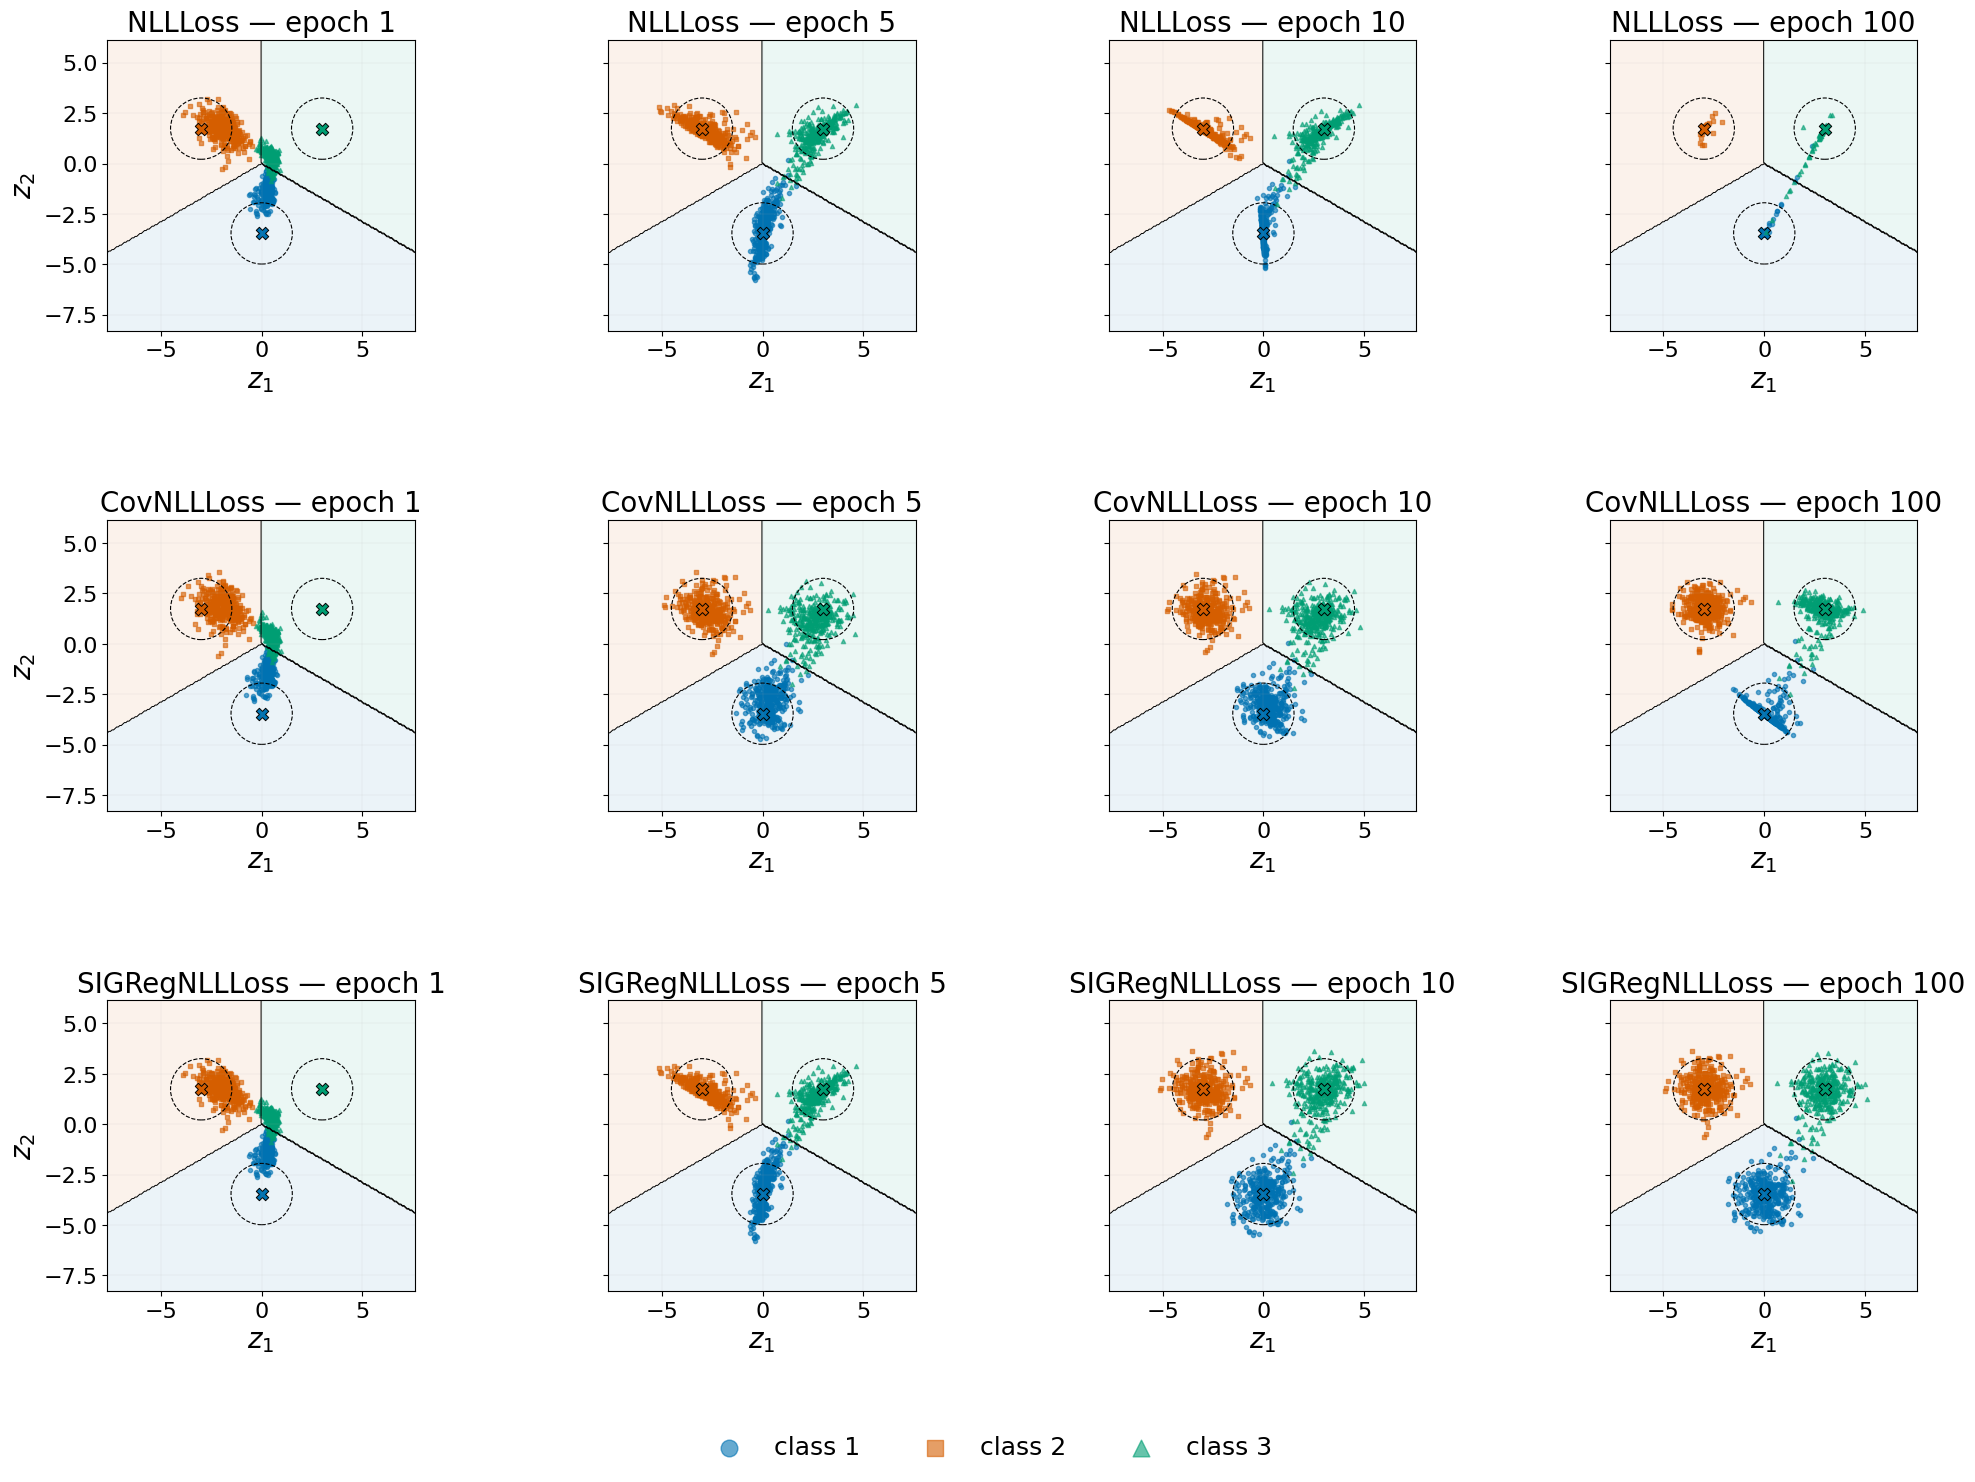

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from matplotlib.patches import Ellipse
from matplotlib.colors import ListedColormap

plt.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 18,
})

Path('plots').mkdir(parents=True, exist_ok=True)
colors = ['#0072B2', '#D55E00', '#009E73']
markers = ['o', 's', '^']


# One coordinate scale for all panels, including head centers and ellipses.
all_points = torch.cat([
    snapshot['embeddings'] for snapshots in embedding_snapshots.values()
    for snapshot in snapshots.values()
] + [snapshot['centers'] for snapshots in embedding_snapshots.values()
     for snapshot in snapshots.values()])
low = all_points.min(0).values.numpy() - 2.5
high = all_points.max(0).values.numpy() + 2.5
xx, yy = np.meshgrid(np.linspace(low[0], high[0], 200),
                     np.linspace(low[1], high[1], 200))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(len(loss_names), len(checkpoint_epochs), figsize=(21, 15),
                         sharex=True, sharey=True, squeeze=False)
for row, loss_name in enumerate(loss_names):
    for col, epoch in enumerate(checkpoint_epochs):
        ax = axes[row, col]
        snapshot = embedding_snapshots[loss_name][epoch]
        Z, Y = snapshot['embeddings'].numpy(), snapshot['labels'].numpy()
        centers = snapshot['centers'].numpy()
        covariance = snapshot['covariance'].numpy()
        inverse_covariance = np.linalg.inv(covariance)
        w = (inverse_covariance @ centers.T).T
        b = (-0.5 * np.sum(centers @ inverse_covariance * centers, axis=1)
             + np.log(snapshot['priors'].numpy().clip(1e-12)))
        regions = (grid @ w.T + b).argmax(1).reshape(xx.shape)
        ax.contourf(xx, yy, regions, levels=np.arange(NUM_CLASSES + 1) - 0.5,
                    cmap=ListedColormap(colors), alpha=0.08)
        ax.contour(xx, yy, regions, levels=np.arange(NUM_CLASSES - 1) + 0.5,
                   colors='black', linewidths=0.7)
        for c in range(NUM_CLASSES):
            mask = Y == c + LABEL_OFFSET
            ax.scatter(Z[mask, 0], Z[mask, 1], s=9, alpha=0.6,
                       color=colors[c], marker=markers[c], label=f'class {c + LABEL_OFFSET}')
            ax.scatter(*centers[c], marker='X', s=80, color=colors[c],
                       edgecolor='black', linewidth=0.7)
            # Fixed spherical covariance: scale the reference circle by sigma.
            radius = 2.15 * np.sqrt(covariance[0, 0])
            ax.add_patch(Ellipse(centers[c], 2 * radius, 2 * radius,
                                 facecolor='none', edgecolor='black', linestyle='--', linewidth=0.8))
        ax.set_title(f'{loss_name} — epoch {epoch}')
        ax.set_xlim(low[0], high[0]); ax.set_ylim(low[1], high[1])
        ax.set_aspect('equal', adjustable='box')
        ax.grid(True, linewidth=0.3, alpha=0.3)
        ax.set_xlabel('$z_1$')
        ax.tick_params(axis='x', labelbottom=True)
        if col == 0:
            ax.set_ylabel('$z_2$')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=NUM_CLASSES, frameon=False, markerscale=4)
fig.tight_layout(rect=(0, 0.07, 1, 1), h_pad=4.0, w_pad=2.0)
fig.savefig('plots/synth_nll_covnll_sigreg_epochs.png', dpi=180, bbox_inches='tight')
plt.show()


## Held-out Gaussianity diagnostics

Evaluate final-epoch models on **all test embeddings**, with the same fixed
diagnostic projections and a finer 129-point integration grid for every method. Report each class's distance from its
fixed target mean, empirical covariance error against $I/D$, and projected
CF discrepancy
$\mathrm{EP}_c/n_c$ (without the sample-count multiplier, for easier comparison).
For scale, report the same discrepancy on a seeded sample drawn directly from
$N(\mu_c,I/D)$ with the same class counts. This reference has finite-sample error.
These values are diagnostics, not calibrated hypothesis-test p-values, and do
not select the training configuration.

CF diagnostics and Q–Q plots standardize residuals by the fixed model
standard deviation $1/\sqrt{D}$. The Q–Q plots compare coordinate and
diagonal projections against $N(0,1)$ quantiles. No empirical standardization
is applied; deviations can reflect mean, scale, or shape mismatch. Matching only
the two coordinate marginals would not establish multivariate Gaussianity.


method          class      n   mean err    cov err     CF error  Gaussian ref
NLLLoss             1   1325     0.0774     0.5544     0.360587      0.000237
NLLLoss             2   1338     0.0114     0.6856     0.378735      0.000790
NLLLoss             3   1337     0.0815     0.5972     0.350560      0.000653
CovNLLLoss          1   1325     0.1571     0.2166     0.097114      0.000237
CovNLLLoss          2   1338     0.0457     0.2101     0.015627      0.000790
CovNLLLoss          3   1337     0.1585     0.2189     0.059932      0.000653
SIGRegNLLLoss       1   1325     0.0478     0.1460     0.001973      0.000237
SIGRegNLLLoss       2   1338     0.0543     0.0457     0.002739      0.000790
SIGRegNLLLoss       3   1337     0.0906     0.1504     0.002554      0.000653


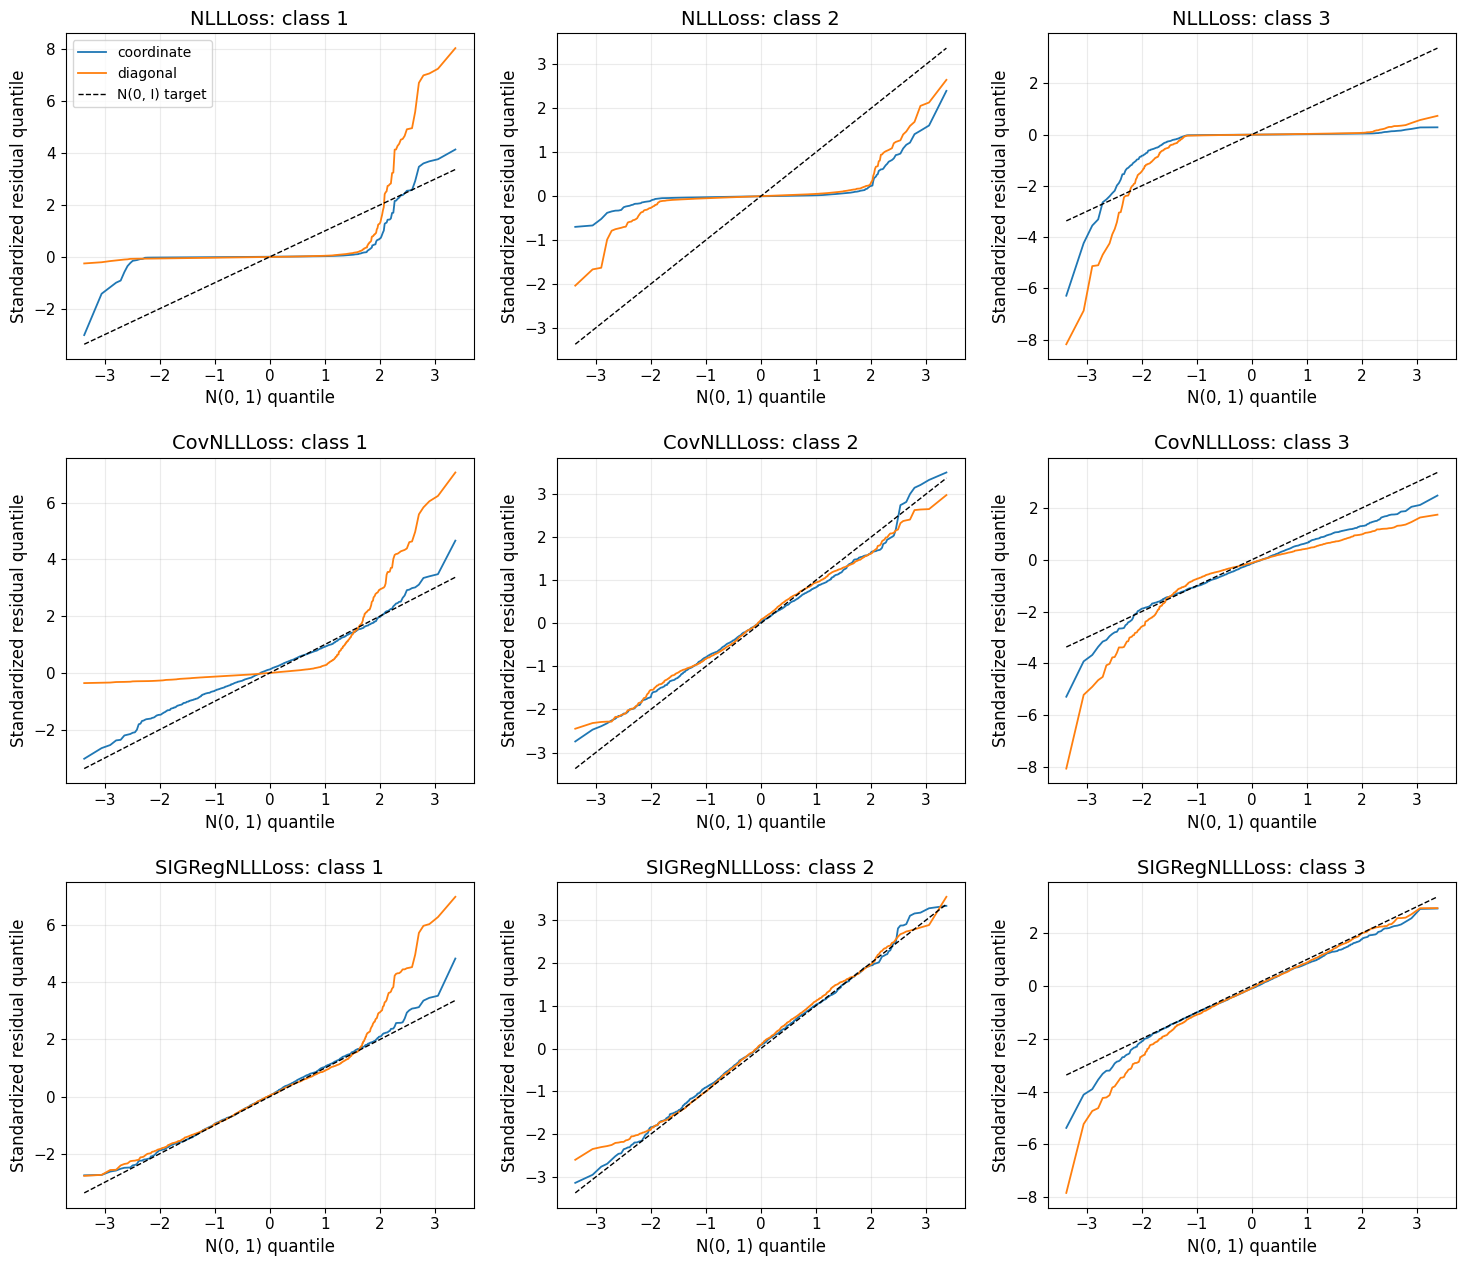

In [8]:
@torch.no_grad()
def heldout_embeddings(model):
    return torch.cat([model.encoder(X) for X, _ in test_ld])


diagnostic_sigreg = ClasswiseSIGReg(
    num_slices=num_slices, seed=8191, num_points=diagnostic_integration_points,
)
diagnostic_labels = test_y - LABEL_OFFSET
reference_gen = torch.Generator().manual_seed(2026)
embedding_dimension = next(iter(comparison_models.values())).head.D
reference_standard_normal = torch.randn(
    len(test_ds), embedding_dimension, generator=reference_gen,
)
diagnostic_rows, heldout_standardized_residuals = [], {}
for loss_name in loss_names:
    model = comparison_models[loss_name]
    centers = model.head.mu.detach()
    variance = model.head.cov_diag[0]
    standard_deviation = variance.sqrt()
    log_variance = variance.log()
    reference_residuals = reference_standard_normal * standard_deviation
    z = heldout_embeddings(model)
    residuals = z - centers[diagnostic_labels]
    heldout_standardized_residuals[loss_name] = residuals / standard_deviation
    ep, counts = diagnostic_sigreg.statistics(
        z, diagnostic_labels, centers, log_variance=log_variance,
    )
    ref_ep, _ = diagnostic_sigreg.statistics(
        reference_residuals + centers[diagnostic_labels], diagnostic_labels, centers,
        log_variance=log_variance,
    )
    for c in range(NUM_CLASSES):
        points = residuals[diagnostic_labels == c]
        n = len(points)
        if n < 2:
            continue
        centered = points - points.mean(0)
        covariance = centered.T @ centered / (n - 1)
        diagnostic_rows.append(dict(
            method=loss_name, class_label=c + LABEL_OFFSET, count=n,
            mean_error=points.mean(0).norm().item(),
            covariance_error=(covariance - model.head.covariance).norm().item(),
            cf_discrepancy=(ep[c] / n).item(),
            reference_cf_discrepancy=(ref_ep[c] / n).item(),
        ))

print(f"{'method':<15} {'class':>5} {'n':>6} {'mean err':>10} {'cov err':>10} {'CF error':>12} {'Gaussian ref':>13}")
for r in diagnostic_rows:
    print(f"{r['method']:<15} {r['class_label']:5d} {r['count']:6d} "
          f"{r['mean_error']:10.4f} {r['covariance_error']:10.4f} "
          f"{r['cf_discrepancy']:12.6f} {r['reference_cf_discrepancy']:13.6f}")

fig, axes = plt.subplots(len(loss_names), NUM_CLASSES, figsize=(15, 13), squeeze=False)
directions = torch.tensor([[1., 0.], [2 ** -0.5, 2 ** -0.5]])
normal = torch.distributions.Normal(0., 1.)
for row, loss_name in enumerate(loss_names):
    for c in range(NUM_CLASSES):
        ax = axes[row, c]
        points = heldout_standardized_residuals[loss_name][diagnostic_labels == c]
        if len(points) < 2:
            continue
        theoretical = normal.icdf((torch.arange(len(points)) + 0.5) / len(points))
        for direction, label in zip(directions, ('coordinate', 'diagonal')):
            observed = (points @ direction).sort().values
            ax.plot(theoretical, observed, linewidth=1.3, label=label)
        ax.plot(theoretical, theoretical, 'k--', linewidth=1, label='N(0, I) target')
        ax.set_title(f'{loss_name}: class {c + LABEL_OFFSET}', fontsize=14)
        ax.set_xlabel('N(0, 1) quantile', fontsize=12)
        ax.set_ylabel('Standardized residual quantile', fontsize=12)
        ax.tick_params(labelsize=11)
        ax.grid(alpha=0.25)
axes[0, 0].legend(fontsize=10)
fig.tight_layout()
fig.savefig('plots/synth_sigreg_heldout_qq.png', dpi=180, bbox_inches='tight')
plt.show()


## Training curves and saved metrics


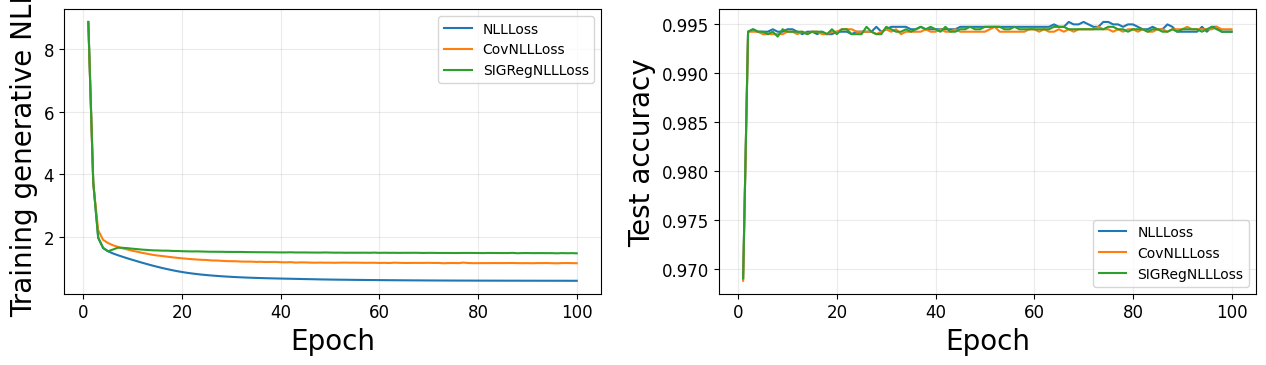

Saved metrics to results/synthetic_sigreg/metrics.json


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for loss_name, history in training_history.items():
    epochs = [r['epoch'] for r in history]
    axes[0].plot(epochs, [r['nll'] for r in history], label=loss_name)
    axes[1].plot(epochs, [r['test_accuracy'] for r in history], label=loss_name)
axes[0].set_ylabel('Training generative NLL')
axes[1].set_ylabel('Test accuracy')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=10)
fig.tight_layout()
fig.savefig('plots/synth_sigreg_training.png', dpi=180, bbox_inches='tight')
plt.show()

output_dir = Path('results/synthetic_sigreg')
output_dir.mkdir(parents=True, exist_ok=True)
reference_head = comparison_models['SIGRegNLLLoss'].head
head_variance = reference_head.cov_diag[0].item()
metrics = {
    'settings': dict(train_size=TRAIN_SIZE, test_size=TEST_SIZE, batch_size=BATCH_SIZE,
                     checkpoint_epochs=checkpoint_epochs, seed=comparison_seed,
                     covariance_type=reference_head.covariance_type, covariance_rule='I / D',
                     embedding_dimension=reference_head.D, fixed_variance=head_variance,
                     standard_deviation=math.sqrt(head_variance),
                     covariance_weight=covariance_weight, gaussianity_weight=gaussianity_weight,
                     num_slices=num_slices, integration_points=num_integration_points, integration_range=[-5, 5],
                     diagnostic_integration_points=diagnostic_integration_points,
                     sigreg_warmup_epochs=sigreg_warmup_epochs, sigreg_ramp_epochs=sigreg_ramp_epochs,
                     class_weighting='n_c / N', class_statistic='n_c * mean_projected_integral',
                     residual_center='fixed simplex mean', residual_scale='fixed model standard deviation',
                     covariance_penalty='standardized covariance versus identity', diagnostic_seed=8191),
    'history': training_history,
    'heldout_diagnostics': diagnostic_rows,
}
(output_dir / 'metrics.json').write_text(json.dumps(metrics, indent=2) + '\n')
print('Saved metrics to', output_dir / 'metrics.json')
